## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [15]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import setup

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Total combinations of features: 255


## Setup

In [4]:
VERSION = 2
VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/chinese_gender/comparison/classification/_<VAR_X>'
METRIC = 'test_auc'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(1020, 25)

In [6]:
cols = ['y','features_id','strategy_id','test_accuracy','test_f1','test_precision','test_recall','test_auc','f_name']
# df_results[cols].query("~y.str.contains('median')").sort_values(METRIC, ascending=False)
df_results[cols].sort_values(METRIC, ascending=False)

,y,features_id,strategy_id,test_accuracy,test_f1,test_precision,test_recall,test_auc,f_name
221,gender_mean,102,1,0.95,0.649123,0.633333,0.666667,0.982456,mean_102_1
102,gender_mean,230,1,0.95,0.650794,0.636364,0.666667,0.982456,mean_230_1
433,gender_mean,161,1,0.90,0.615789,0.606061,0.633333,0.979123,mean_161_1
187,gender_mean,228,1,0.90,0.633333,0.633333,0.633333,0.975789,mean_228_1
9,gender_mean,37,1,0.90,0.613757,0.599327,0.629630,0.975756,mean_37_1
...,...,...,...,...,...,...,...,...,...
546,gender_median,2,3,0.65,0.468627,0.434343,0.509259,0.629481,median_2_3
180,gender_mean,3,1,0.70,0.472222,0.492063,0.485185,0.612211,mean_3_1
454,gender_mean,2,2,0.50,0.381264,0.347222,0.462963,0.602694,mean_2_2
329,gender_mean,21,1,0.70,0.472222,0.492063,0.485185,0.598810,mean_21_1


In [7]:
best_id = df_results[METRIC].idxmax()
best_id

102

In [8]:
df_results.loc[best_id]

strategy_id                                                       1
features_id                                                     230
y                                                       gender_mean
features          [ngender_r, ngender_n, gender_nw, mean_ngender...
nfeatures                                                         6
cat_features                                            [gender_nw]
best_params       {'depth': 4, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'MultiClass': 0.06496664475111533},...
best_iteration                                                   23
test_size                                                       0.2
random_state                                                  12345
loss_function                                            MultiClass
eval_metric                                              MultiClass
train_eval                                                 0.064967
test_accuracy                                   

In [9]:
df_results.loc[best_id].features

['ngender_r',
 'ngender_n',
 'gender_nw',
 'mean_ngender_rn',
 'mean_ngender_nw',
 'mean_ngender_rnw']

In [16]:
df_results.loc[best_id].strategy_id, setup.STRATEGY[df_results.loc[best_id].strategy_id]

(1, {'cuts': [0.445, 0.541], 'gt_agg': 'mean'})

In [11]:
metric = df_results.loc[best_id].y.replace('gender_','')
f_name = DIR.replace('<VAR_X>', metric)
f_name = f"{f_name}/{metric}_{df_results.loc[best_id].features_id}_{df_results.loc[best_id].strategy_id}"
f_name

'../../results/v2/chinese_gender/comparison/classification/_mean/mean_230_1'

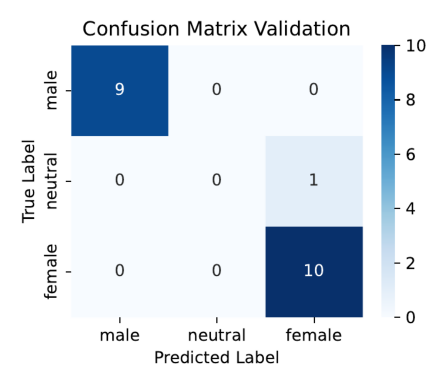

In [12]:
# predictions
fn = f"{f_name}_confusion_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



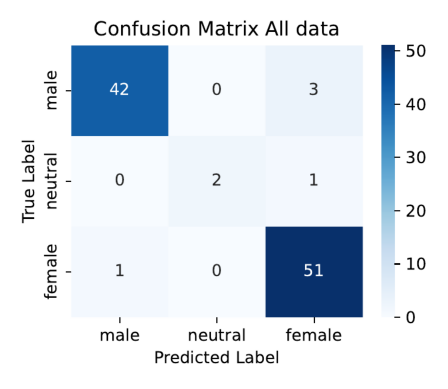

In [13]:
# predictions
fn = f"{f_name}_confusion_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



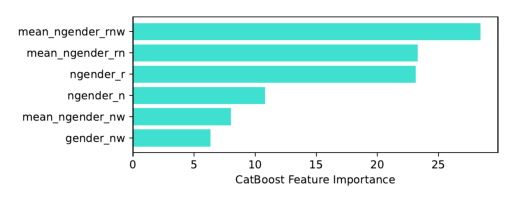

In [14]:
# predicitos
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

